# Actividad 4. Pipeline concurrente y eficiencia computacional

David Santiago Iriarte Zamora y Jose Adrian Trochez Cuellar · Grupo 12

Optimizamos el modelo de la actividad 3 y conservamos la calidad predictiva. Este notebook analiza mediciones reales con ventana OpenCV; el script `src/pipeline_a4.py` contiene captura, inferencia, colas seguras y presentación. El informe tiene cinco páginas.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir() and (p / 'datos').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code
pd.set_option('display.max_columns', 20)
print('Carpeta de trabajo:', ROOT.name)


Carpeta de trabajo: Actividad 4


## 1. Protocolo y fuente

El video público de DrGFreeman tiene 904 cuadros. Usamos el mismo AVI, ROI y modelo en todos los casos. El benchmark 2 × 2 separa efecto de hilos y grafo: tres repeticiones, orden alternado y 30 inferencias de calentamiento. La ejecución de referencia ya está guardada; repetir con ventana requiere OpenCV de escritorio. Los FPS son del ciclo imshow/waitKey, no una medición física del panel.

In [2]:
RES = ROOT/'resultados'
display(json.loads((ROOT/'datos/video_metadata.json').read_text()))
display(json.loads((ROOT/'modelo/config_A3.json').read_text())['versiones'])
print('Los benchmarks entregados usaron ventana Cocoa de OpenCV 4.14.0 y CPU.')


{'source': 'rps_demo.gif',
 'frames': 904,
 'width': 640,
 'height': 400,
 'duration_ms_values': [60, 70],
 'duration_s': 60.27,
 'fps_contenedor': 14.285714285714286,
 'codec': 'MJPG',
 'nota': 'Conversión para VideoCapture; conservar GIF original y reconocer cualquier diferencia de cadencia.'}

{'python': '3.12.11',
 'tensorflow': '2.21.0',
 'keras': '3.15.1',
 'numpy': '2.5.3',
 'plataforma': 'macOS-26.6.2-arm64-arm-64bit',
 'cpu_logicos': 12,
 'dispositivo': 'CPU'}

Los benchmarks entregados usaron ventana Cocoa de OpenCV 4.14.0 y CPU.


## 2. Arquitectura y código completo

Captura entrega paquetes con id, imagen y tiempos a una FIFO acotada. Inferencia añade logits sin sustituir la imagen y los entrega a otra FIFO. El hilo principal dibuja y presenta; un Event, centinelas y una cola de errores coordinan el cierre. La referencia secuencial usa las mismas funciones. Elegimos capacidad 1 en la versión final tras medir sensibilidad.

In [3]:
import inspect
import pipeline_a4 as pipeline
for fn in [pipeline.preparar_frame,pipeline.motor,pipeline.benchmark]:
    display(Code(inspect.getsource(fn),language='python'))


def preparar_frame(frame,roi=ROI):
    x1,y1,x2,y2=roi
    crop=frame[y1:y2,x1:x2]
    if not crop.size:raise ValueError('ROI fuera del cuadro')
    crop=cv2.rotate(crop,cv2.ROTATE_90_CLOCKWISE)
    rgb=cv2.cvtColor(crop,cv2.COLOR_BGR2RGB)
    r,g,b=cv2.split(rgb.astype('float32'))
    green=(g>1.15*r)&(g>1.15*b)&(g>45)
    active=float((~green).mean())>.12
    return letterbox(rgb).astype('float32')[None],active

def motor(model,graph):
    if graph:
        infer=tf.function(lambda x:model(x,training=False),input_signature=[tf.TensorSpec((1,128,128,3),tf.float32)])
    else:
        infer=lambda x:model(x,training=False)
    def call(x):
        return infer(tf.convert_to_tensor(x)).numpy()[0]
    # Calentamiento excluido del cronómetro; materialización sincroniza el resultado.
    x=np.full((1,128,128,3),127,dtype='float32')
    for _ in range(30):call(x)
    return call

def benchmark(model,mode,rep=0,display=False,loops=1,pace=False,video=VIDEO,save_example=True,pace_fps=None,queue_size=2):
    threaded=mode.startswith('hilos');graph=mode.endswith('grafo')
    infer=motor(model,graph)
    if queue_size<1:raise ValueError('La capacidad de cola debe ser positiva')
    stop=threading.Event();errors=queue.Queue();capture_q=queue.Queue(maxsize=queue_size);result_q=queue.Queue(maxsize=queue_size)
    process=psutil.Process();resources=[];records=[];start=0.;last_display=0.;expected_frames=None;cancelled=False
    def sample():
        process.cpu_percent(None)
        while not stop.wait(.1):
            resources.append({'s':time.perf_counter()-start,'cpu_pct_un_nucleo':process.cpu_percent(None),'rss_mb':process.memory_info().rss/2**20})
    def put(q,obj):
        while not stop.is_set():
            try:q.put(obj,timeout=.1);return True
            except queue.Full:pass
        return False
    def lanzar_error():
        # Una sola operación: dos consumidores no pueden bloquearse por leer el mismo error.
        try:message=errors.get_nowait()
        except queue.Empty:return
        raise RuntimeError(message)
    def get(q):
        while not stop.is_set():
            lanzar_error()
            try:return q.get(timeout=.1)
            except queue.Empty:pass
        return None
    def frames():
        nonlocal expected_frames
        fid=0
        for loop in range(loops):
            cap=cv2.VideoCapture(str(video))
            if not cap.isOpened():raise FileNotFoundError(video)
            count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            expected_frames=count*loops if count>0 else None
            fps=pace_fps or cap.get(cv2.CAP_PROP_FPS);frame_in_loop=0
            try:
                while not stop.is_set():
                    if pace:
                        wait=start+fid/fps-time.perf_counter()
                        if wait>0:stop.wait(wait)
                    t0=time.perf_counter();ok,frame=cap.read();t1=time.perf_counter()
                    if not ok:break
                    yield {'id':fid,'loop':loop,'frame_video':frame_in_loop,'frame':frame,'t0':t0,'lectura_ms':1000*(t1-t0),'t_captura':t1}
                    fid+=1;frame_in_loop+=1
            finally:cap.release()
    def calculate(item):
        a=time.perf_counter();x,active=preparar_frame(item['frame']);b=time.perf_counter()
        logits=infer(x);c=time.perf_counter()
        item.update(logits=logits,active=active,pre_ms=1000*(b-a),infer_ms=1000*(c-b),
                    cola_captura_ms=1000*(a-item['t_captura']),t_inferencia=c)
        return item
    def capture():
        try:
            for item in frames():
                if not put(capture_q,item):break
            put(capture_q,None)
        except BaseException:errors.put(traceback.format_exc());put(capture_q,None)
    def worker():
        try:
            while not stop.is_set():
                item=get(capture_q)
                if item is None:break
                if not put(result_q,calculate(item)):break
            put(result_q,None)
        except BaseException:errors.put(traceback.format_exc());put(result_q,None)
    def present(item):
        nonlocal last_display
        a=time.perf_counter();out,pred,conf=dibujar(item['frame'],item['logits'],item['active'],mode,item['id']);b=time.perf_counter()
        if display:
            cv2.imshow('U3 - Reconocimiento de gestos',out)
            if cv2.waitKey(1)&0xff==ord('q'):stop.set()
        c=time.perf_counter()
        record={'id':item['id'],'loop':item['loop'],'frame_video':item['frame_video'],'mode':mode,'rep':rep,
                'lectura_ms':item['lectura_ms'],'pre_ms':item['pre_ms'],'infer_ms':item['infer_ms'],
                'cola_captura_ms':item['cola_captura_ms'],'cola_salida_ms':1000*(a-item['t_inferencia']),
                'dibujo_ms':1000*(b-a),'presentacion_ms':1000*(c-b),'latencia_ms':1000*(c-item['t0']),
                'intervalo_ms':1000*(c-last_display) if las

## 3. Repetir la medición (opcional)

Dejamos el modo de lectura de resultados como predeterminado. Activar la variable abre una ventana y ejecuta 12 corridas. El tag `nueva` evita sustituir los CSV originales. Para la configuración final: `--modes hilos_grafo --queue-size 1`. Para un minuto a entrada controlada: añadir `--loops 4 --pace --pace-fps 60 --reps 1`. No ejecutar entrenamiento al mismo tiempo.

In [4]:
REPETIR_BENCHMARK = False
if REPETIR_BENCHMARK:
    import subprocess
    subprocess.run([sys.executable,str(ROOT/'src/pipeline_a4.py'),'--display',
                    '--reps','3','--tag','nueva'],check=True,cwd=ROOT)


## 4. Comparación antes/después

In [5]:
from analizar_a4 import run as analizar
analizar()
visual=pd.read_csv(RES/'visual_resumen.csv')
cola=pd.read_csv(RES/'cola1_resumen.csv')
sostenido=pd.read_csv(RES/'sostenido60_resumen.csv')
cols=['fps','infer_media_ms','latencia_media_ms','latencia_p95_ms','cpu_equivalente_pct','rss_max_mb']
display(visual.groupby('mode')[cols].agg(['mean','std']))
display(cola[cols])
display(pd.read_csv(RES/'tiempos_etapas.csv',index_col=0))


                              fps        latencia_media_ms        latencia_p95_ms         infer_media_ms        cpu_equivalente_pct        rss_max_mb          fps_ventana_min       
                             mean    std              mean    std            mean     std           mean    std                mean    std       mean      std            mean    std
configuracion                                                                                                                                                                        
secuencial_eager · cola 2  22.251  0.301            44.930  0.603          47.509   1.769         31.987  0.554              77.146  0.321    414.281  126.925          21.818  0.678
hilos_eager · cola 2       30.455  1.110           143.333  4.867         158.491  19.103         32.376  1.186             107.263  0.830    368.495   26.800          28.691  2.950
secuencial_grafo · cola 2  60.925  0.330            16.401  0.091          16.983   0.289 

fps           infer_media_ms            \
                       mean       std           mean       std   
mode                                                             
hilos_eager       30.455317  1.110394      32.376237  1.185768   
hilos_grafo       81.083505  0.560698       3.114152  0.185287   
secuencial_eager  22.251045  0.300906      31.986891  0.553546   
secuencial_grafo  60.924890  0.329756       2.880432  0.063051   

                 latencia_media_ms           latencia_p95_ms             \
                              mean       std            mean        std   
mode                                                                      
hilos_eager             143.333013  4.867276      158.490659  19.103348   
hilos_grafo              85.926500  0.610762       87.505557   0.312186   
secuencial_eager         44.930417  0.602586       47.508997   1.769061   
secuencial_grafo         16.401041  0.090768       16.983393   0.289282   

                 cpu_equivalente_pct            rss_max_mb              
                                mean       std        mean         std  
mode                                                                    
hilos_eager               107.262811  0.829872  368.494792   26.800065  
hilos_grafo                57.587149  3.458332  390.723958    7.994632  
secuencial_eager           77.146104  0.320890  414.281250  126.925274  
secuencial_grafo           38.965559  0.173100  383.708333    8.026101

,fps,infer_media_ms,latencia_media_ms,latencia_p95_ms,cpu_equivalente_pct,rss_max_mb
0,80.566758,3.151075,61.635619,63.148783,56.360949,602.984375
1,81.030193,3.151073,61.455103,62.605492,58.108597,559.250000
2,80.771456,3.273124,61.674946,62.539712,60.432898,565.687500


,lectura_ms,pre_ms,infer_ms,dibujo_ms,presentacion_ms
secuencial_eager,0.644958,0.377701,31.986891,0.060394,11.855899
hilos_eager,0.875830,0.460599,32.376237,0.082593,12.069727
secuencial_grafo,0.859392,0.547702,2.880432,0.063380,12.045773
hilos_grafo,1.047435,0.648578,3.114152,0.125418,12.181706


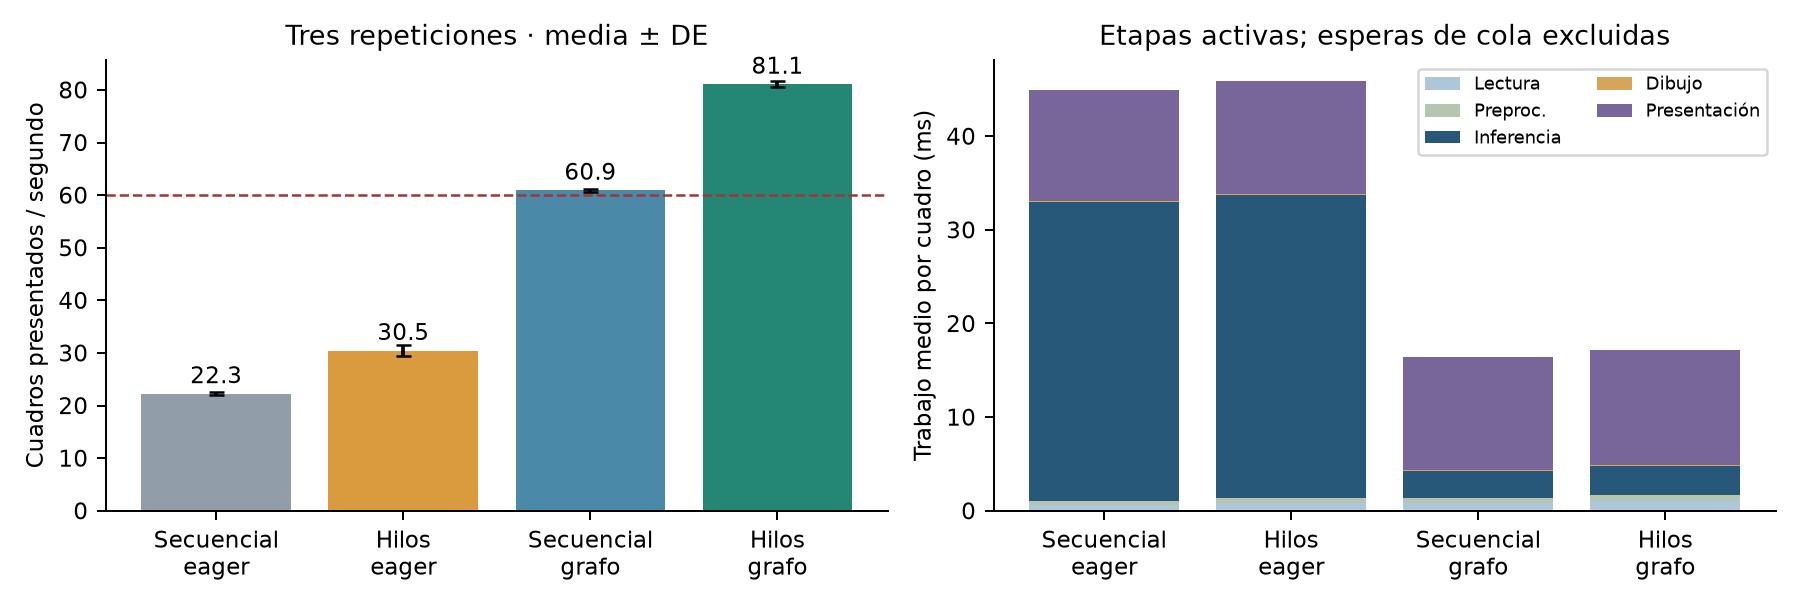

In [6]:
display(Image(filename=str(ROOT/'figuras/rendimiento.png')))

**Lectura:** el grafo baja la inferencia de unos 32 a 3 ms. Los hilos permiten solaparla con unos 12 ms de presentación. La CPU equivalente usa 100 % por núcleo ocupado, no por máquina completa. El RSS incluye bibliotecas y cachés; no atribuimos toda diferencia de memoria entre procesos al tamaño de las colas. TensorFlow no vio GPU.

## 5. Latencia, colas y estabilidad

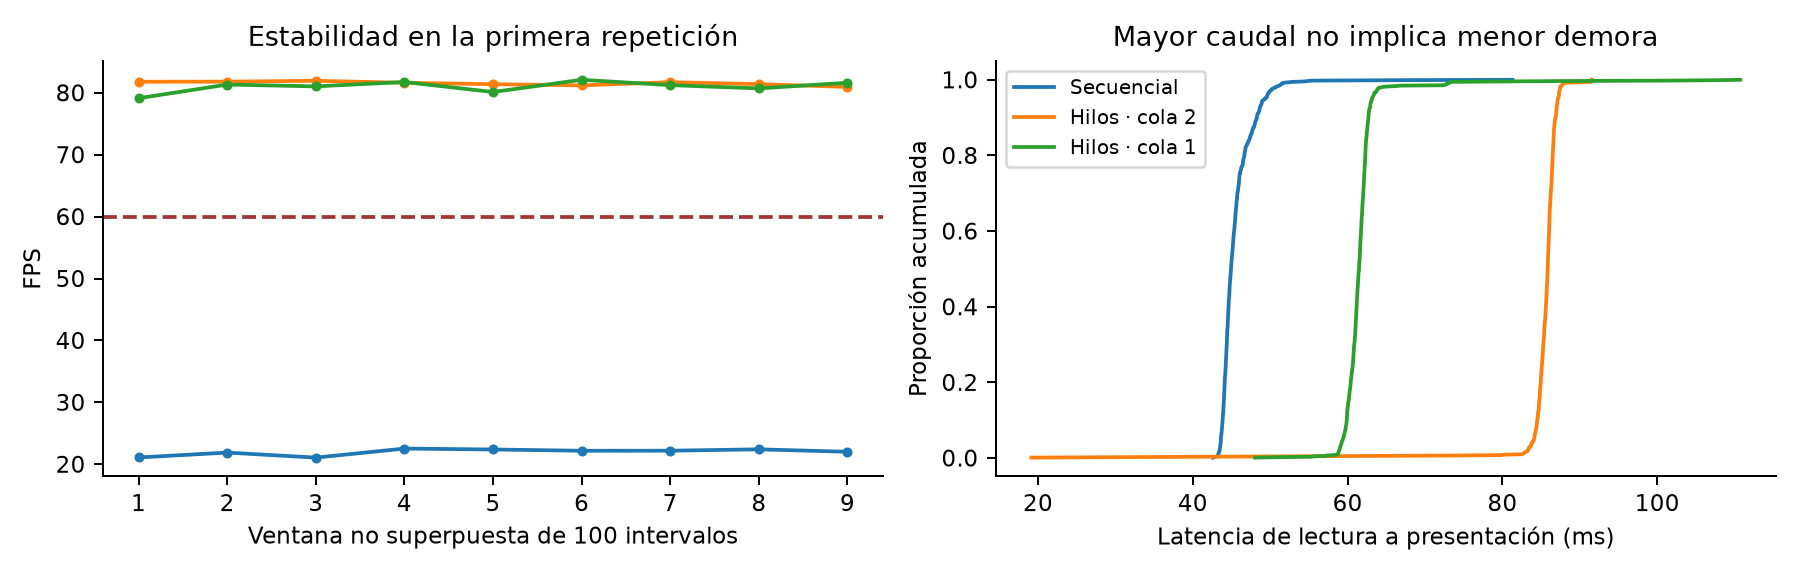

In [7]:
display(Image(filename=str(ROOT/'figuras/latencia_estabilidad.png')))

In [8]:
columns=['fps','latencia_media_ms','latencia_p50_ms','latencia_p95_ms','latencia_p99_ms','fps_ventana_min']
display(visual.groupby('mode')[columns].mean())
display(cola[columns])
display(sostenido[columns])
assert (cola.fps_ventana_min > 60).all()
assert cola.sin_perdidas.all() and sostenido.sin_perdidas.all()


,fps,latencia_media_ms,latencia_p50_ms,latencia_p95_ms,latencia_p99_ms,fps_ventana_min
mode,,,,,,
hilos_eager,30.455317,143.333013,140.644993,158.490659,175.918182,28.691011
hilos_grafo,81.083505,85.926500,86.209090,87.505557,88.460793,80.560726
secuencial_eager,22.251045,44.930417,44.532486,47.508997,50.264687,21.818067
secuencial_grafo,60.924890,16.401041,16.389757,16.983393,17.371645,60.300709


,fps,latencia_media_ms,latencia_p50_ms,latencia_p95_ms,latencia_p99_ms,fps_ventana_min
0,80.566758,61.635619,61.472583,63.148783,72.827919,79.123029
1,81.030193,61.455103,61.614624,62.605492,64.353833,80.218700
2,80.771456,61.674946,61.876605,62.539712,62.717625,80.237004


,fps,latencia_media_ms,latencia_p50_ms,latencia_p95_ms,latencia_p99_ms,fps_ventana_min
0,59.996494,16.576541,16.476375,16.872198,17.793985,59.916633


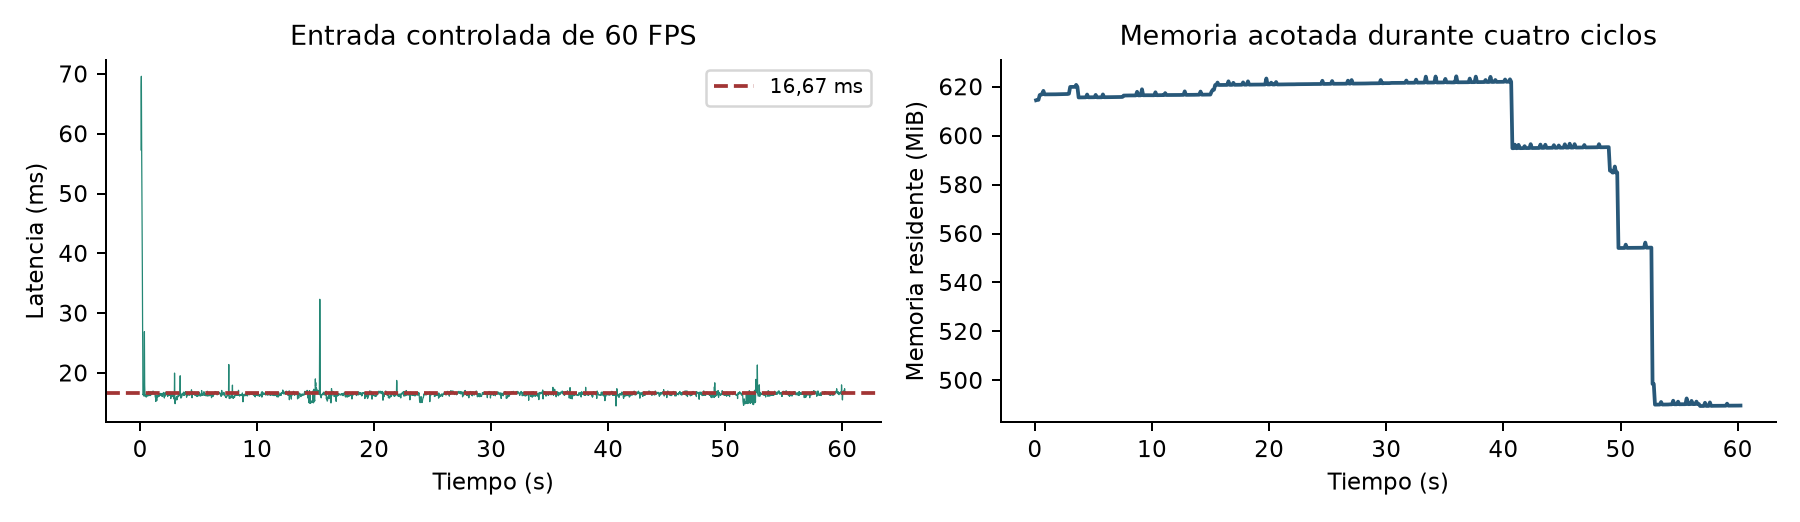

In [9]:
display(Image(filename=str(ROOT/'figuras/sostenido.png')))

**Lectura:** cola 1 reduce la latencia media de 85,93 a 61,59 ms, manteniendo aproximadamente 81 FPS. Con entrada a 60 FPS procesa 3.616 cuadros durante 60,27 s y logra 59,996 FPS; latencia media 16,58 ms y p95 16,87 ms. Esa prueba no supera 60 porque programamos esa tasa de llegada. Reproducir cuatro veces el mismo video evalúa estabilidad, no nueva diversidad.

## 6. Equivalencia de calidad y manejo de fallos

In [10]:
verification=json.loads((RES/'verificacion.json').read_text())
display(pd.DataFrame(verification['equivalencia']))
assert all(r['cambios_clase']==0 for r in verification['equivalencia'])
assert verification['error_fuente_manejado'] and not verification['hilos_residuales']
revision=json.loads((RES/'revision_concurrencia.json').read_text())
assert revision['hilos_residuales']==0
display(revision)
eq=pd.read_csv(RES/'equivalencia_video.csv')
display(eq)
assert eq.clases_distintas.sum()==0
for path in RES.glob('*_frames.csv'):
    frame=pd.read_csv(path)
    assert frame.id.tolist()==list(range(len(frame)))
print('Calidad equivalente, orden conservado y cierre por fallo verificado.')


,particion,n,cambios_clase,max_delta_prob,accuracy_eager,accuracy_grafo
0,test,437,0,5.364418e-07,1.000000,1.000000
1,externo,372,0,2.861023e-06,0.645161,0.645161


{'comprobaciones': ['Fuente completa, cola 1: 6 ids en orden y finalización completa',
  'Cancelación simulada, cola 1: no se informa como video completo',
  'Fuente fallida, cola 1: 20 cierres correctos',
  'Fuente completa, cola 2: 6 ids en orden y finalización completa',
  'Cancelación simulada, cola 2: no se informa como video completo',
  'Fuente fallida, cola 2: 20 cierres correctos'],
 'hilos_residuales': 0,
 'nota': 'Pruebas funcionales con fuente, motor y GUI simulados; no son mediciones de rendimiento.',
 'sha256_version_medida': '013961e2593e0c69de4b3050f5d11fa98126a913e6dc500634aa28372837a71d',
 'sha256_version_revisada': '768aed88fdcff5f9ec8086ccb6d6373c709120405f377c28e94df79ce15d5c3e',
 'cambio': 'Lectura atómica de errores y comprobación de cancelación/conteo total. Pesos y etapas de procesamiento sin cambios.'}

,archivo,cuadros,clases_distintas,max_delta_confianza
0,cola1_hilos_grafo_r0_frames.csv,904,0,0.000002
1,cola1_hilos_grafo_r1_frames.csv,904,0,0.000002
2,cola1_hilos_grafo_r2_frames.csv,904,0,0.000002
3,sostenido60_hilos_grafo_r0_frames.csv,3616,0,0.000002
4,visual_hilos_eager_r0_frames.csv,904,0,0.000000
5,visual_hilos_eager_r1_frames.csv,904,0,0.000000
6,visual_hilos_eager_r2_frames.csv,904,0,0.000000
7,visual_hilos_grafo_r0_frames.csv,904,0,0.000002
8,visual_hilos_grafo_r1_frames.csv,904,0,0.000002
9,visual_hilos_grafo_r2_frames.csv,904,0,0.000002


Calidad equivalente, orden conservado y cierre por fallo verificado.


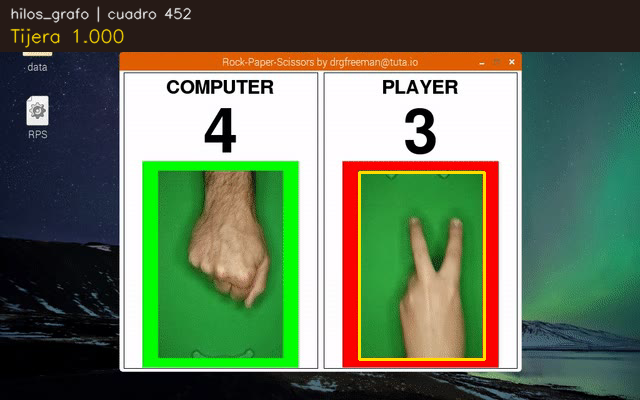

In [11]:
display(Image(filename=str(ROOT/'figuras/ejemplo_hilos_grafo.png')))

**Lectura:** no cambió ninguna clase en 809 imágenes. En los 17.176 registros de video la equivalencia también fue total; esos registros incluyen repeticiones. El video carece de etiquetas independientes por cuadro: equivalencia no significa exactitud perfecta. Su interfaz original pertenece a la fuente; nuestras anotaciones son la franja superior y la ROI. La fuente inexistente produjo una excepción controlada y no dejó hilos residuales. Después reforzamos la lectura de la cola de errores y comprobamos 40 fallos de fuente y cancelaciones simuladas. Estas pruebas funcionales no se usan para calcular FPS.

## 7. Conclusión y límites

El pipeline final procesa 3,63 veces más cuadros por segundo que la referencia sin cambiar sus predicciones. La presentación es el nuevo cuello de botella. La ROI fija, el fondo verde y el giro restringen el alcance. El benchmark mide el ciclo visual del software, no cámara-fotón ni refresco físico. No elimina las limitaciones de generalización del clasificador. Para una cámara nueva necesitamos localizar la mano y evaluar datos etiquetados independientes.

## Referencias

de la Bruère-Terreault, J. (s. f.). *rps-cv* [Software y demostración]. GitHub. https://github.com/DrGFreeman/rps-cv

OpenCV Team. (s. f.). *Performance measurement and improvement techniques*. https://docs.opencv.org/4.x/dc/d71/tutorial_py_optimization.html

Python Software Foundation. (s. f.). *threading - Thread-based parallelism*. https://docs.python.org/3.12/library/threading.html

Python Software Foundation. (s. f.). *queue - A synchronized queue class*. https://docs.python.org/3.12/library/queue.html

TensorFlow. (s. f.). *Better performance with tf.function*. https://www.tensorflow.org/guide/function

Ultralytics. (s. f.). *Model benchmarking with Ultralytics YOLO*. https://docs.ultralytics.com/modes/benchmark/